(sec-7-3)=
# 7.3 The Periodogram, Bartlett and Welch Methods

A sleep technician looking at an EEG wants to know how much alpha activity there is; an HRV analyst wants the power in the low- and high-frequency bands of an RR series; an engineer validating an ECG front end wants the noise floor in µV²/Hz. All three questions are about the power spectral density of [Section 7.2](02_power_spectral_density.ipynb), and all three have to be answered from a single, finite recording. The definition of the PSD contains an expectation over an ensemble of realizations and a limit of infinite length. Neither is available in practice, so we need an *estimator*: a recipe that turns $N$ samples into a curve that is close to $S_x(f)$ and comes with an honest statement of how close.

The obvious recipe is to drop the expectation and the limit from the definition and compute $|X_N|^2/N$ from the one record we have. This is the **periodogram**, and it is the starting point of every nonparametric method. In this section I show that it has two defects, a bias that smears the spectrum and a variance that does not shrink with more data, and I derive both from the equations of [Section 7.2](02_power_spectral_density.ipynb#sec-7-2). Bartlett's and Welch's methods then trade a little of the first defect for a large reduction in the second. We implement Welch's method from scratch, match it to `scipy.signal.welch` to machine precision, attach $\chi^2$ confidence intervals to it, and use it on real recordings: the spectrum of an ECG and the alpha rhythm of an EEG with the eyes open and closed.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import wfdb
import mne
from scipy import signal, stats

plt.style.use("../bsp.mplstyle")
C = plt.rcParams["axes.prop_cycle"].by_key()["color"]
np.set_printoptions(precision=4, suppress=True)
mne.set_log_level("ERROR")
rng = np.random.default_rng(42)

(sec-7-3-1)=
## 7.3.1 The Periodogram

Given $N$ samples $x[0], \ldots, x[N-1]$ of a zero-mean WSS process, the **periodogram** is

(eq-7-22)=
\begin{equation*}
\hat{S}_P(e^{j\Omega}) = \frac{1}{N}\left|\sum_{n=0}^{N-1} x[n]\,e^{-j\Omega n}\right|^2 . \tag{7.22}
\end{equation*}

It is the quantity inside the expectation of the PSD definition [(7.12)](02_power_spectral_density.ipynb#eq-7-12), evaluated for the one record we have. The name goes back to {cite:t}`schuster1898`, who used it to search for hidden periodicities in meteorological data. In practice we evaluate it at the DFT frequencies $\Omega_k = 2\pi k/N$, where the sum is the DFT $X[k]$, and we convert to a one-sided density in hertz exactly as in [Section 7.2.4](02_power_spectral_density.ipynb#sec-7-2-4): divide by $f_s$ and double every bin except DC and, for even $N$, the Nyquist bin,

(eq-7-23)=
\begin{equation*}
\hat{S}_P(f_k) = \frac{c_k}{N f_s}\,\big|X[k]\big|^2, \qquad f_k = \frac{k f_s}{N}, \qquad c_k = \begin{cases} 1, & k = 0 \text{ or } k = N/2, \\ 2, & \text{otherwise}. \end{cases} \tag{7.23}
\end{equation*}

With this scaling the sum of the periodogram times the bin width $f_s/N$ equals the mean square of the record, by Parseval's relation for the DFT. That is the discrete version of "area equals power," and it is the first check I run on any PSD code.

In [2]:
def periodogram(x, fs):
    """One-sided periodogram in units^2/Hz, equation (12.23)."""
    N = x.size
    P = np.abs(np.fft.rfft(x)) ** 2 / (N * fs)
    P[1:(N + 1) // 2] *= 2
    return np.fft.rfftfreq(N, 1 / fs), P


fs = 360.0
x = rng.normal(0, 0.05, 2048)                      # 50 uV RMS white noise, in mV
f, P = periodogram(x, fs)
f_sp, P_sp = signal.periodogram(x, fs=fs, detrend=False)

print(f"max |ours - scipy|      : {np.max(np.abs(P - P_sp)):.1e} mV^2/Hz")
print(f"sum(P) * df             : {P.sum() * fs / x.size:.6f} mV^2")
print(f"mean square of x        : {np.mean(x**2):.6f} mV^2")
print(f"theoretical level 2s^2/fs: {2 * 0.05**2 / fs:.2e} mV^2/Hz, mean of P: {P[1:-1].mean():.2e}")

max |ours - scipy|      : 6.1e-20 mV^2/Hz
sum(P) * df             : 0.002509 mV^2
mean square of x        : 0.002509 mV^2
theoretical level 2s^2/fs: 1.39e-05 mV^2/Hz, mean of P: 1.39e-05


### The periodogram is the transform of the biased autocorrelation

There is a second way to read [(7.22)](#eq-7-22), and it connects the periodogram to the autocorrelation estimators of [Section 7.1.6](01_random_processes.ipynb#sec-7-1-6). Expanding the squared magnitude as a double sum, as in Step 1 of the Wiener–Khinchin derivation, but *without* taking an expectation,

$$
\begin{aligned}
\hat{S}_P(e^{j\Omega}) &= \frac{1}{N}\sum_{n=0}^{N-1}\sum_{m=0}^{N-1} x[n]\,x[m]\,e^{-j\Omega(n - m)} \\
&= \sum_{k=-(N-1)}^{N-1}\left(\frac{1}{N}\sum_{m} x[m + k]\,x[m]\right) e^{-j\Omega k} .
\end{aligned}
$$

In the second line we grouped the pairs $(n, m)$ by their lag $k = n - m$; the inner sum runs over the $N - |k|$ values of $m$ for which both samples exist. The bracket is exactly the biased estimate $\hat{r}_x^{\,b}[k]$ of equation [(7.10)](01_random_processes.ipynb#eq-7-10), so

(eq-7-24)=
\begin{equation*}
\hat{S}_P(e^{j\Omega}) = \sum_{k=-(N-1)}^{N-1} \hat{r}_x^{\,b}[k]\,e^{-j\Omega k}. \tag{7.24}
\end{equation*}

The periodogram is the Wiener–Khinchin theorem applied to an estimated autocorrelation. Two consequences are immediate. Because the periodogram is a squared magnitude, it is never negative, which confirms that the biased estimate always yields a valid spectrum (the unbiased one does not). And because $\hat{r}_x^{\,b}[k]$ is computed from only $N - |k|$ products, the large lags are poorly estimated, yet [(7.24)](#eq-7-24) gives them the same weight as the small lags. This is the root of the variance problem we meet in [Section 7.3.3](#sec-7-3-3). We confirm [(7.24)](#eq-7-24) numerically at a few frequencies.

In [3]:
N = 300
x = rng.normal(0, 1, N)
r_b = np.correlate(x, x, mode="full") / N           # lags -(N-1) .. N-1
lags = np.arange(-(N - 1), N)
for Omega in [0.1, 1.0, 2.5]:
    direct = np.abs(np.sum(x * np.exp(-1j * Omega * np.arange(N)))) ** 2 / N
    via_r = np.sum(r_b * np.exp(-1j * Omega * lags)).real
    print(f"Omega = {Omega:3.1f} rad: |X_N|^2/N = {direct:8.4f},  DTFT of r_b = {via_r:8.4f}")

Omega = 0.1 rad: |X_N|^2/N =   0.0842,  DTFT of r_b =   0.0842
Omega = 1.0 rad: |X_N|^2/N =   0.4931,  DTFT of r_b =   0.4931
Omega = 2.5 rad: |X_N|^2/N =   0.2187,  DTFT of r_b =   0.2187


(sec-7-3-2)=
## 7.3.2 Bias: the Fejér Kernel and Spectral Leakage

Taking the expectation of [(7.24)](#eq-7-24) and using $\mathbb{E}\{\hat{r}_x^{\,b}[k]\} = (1 - |k|/N)R_x[k]$ from [(7.11)](01_random_processes.ipynb#eq-7-11) brings us back to equation [(7.13)](02_power_spectral_density.ipynb#eq-7-13) of the previous section:

$$
\mathbb{E}\{\hat{S}_P(e^{j\Omega})\} = \sum_{k=-(N-1)}^{N-1} w_B[k]\,R_x[k]\,e^{-j\Omega k}, \qquad w_B[k] = \begin{cases} 1 - |k|/N, & |k| < N, \\ 0, & \text{otherwise}. \end{cases}
$$

The true autocorrelation is multiplied by a triangle (the Bartlett lag window) before the Fourier transform. To see what this does in the frequency domain we need the DTFT of the triangle.

**Step 1: write the triangle as a window autocorrelation.** Let $w_R[n] = 1$ for $0 \le n \le N-1$ and zero otherwise. The number of positions at which $w_R[n]$ and $w_R[n + k]$ are both one is $N - |k|$, so

$$
w_B[k] = \frac{1}{N}\sum_{n} w_R[n]\,w_R[n + k].
$$

**Step 2: transform it.** The DTFT of a deterministic autocorrelation $\sum_n v[n]v[n+k]$ is $|V(e^{j\Omega})|^2$ (the same calculation as Step 1 of [Section 7.2.3](02_power_spectral_density.ipynb#sec-7-2-3), without the expectation). The DTFT of the rectangle is a finite geometric series, which we summed in Section 10.4:

$$
W_R(e^{j\Omega}) = \sum_{n=0}^{N-1} e^{-j\Omega n} = \frac{1 - e^{-j\Omega N}}{1 - e^{-j\Omega}} = e^{-j\Omega(N-1)/2}\,\frac{\sin(N\Omega/2)}{\sin(\Omega/2)} .
$$

Hence the DTFT of the triangle is the **Fejér kernel**

(eq-7-25)=
\begin{equation*}
F_N(\Omega) = \frac{1}{N}\,\big|W_R(e^{j\Omega})\big|^2 = \frac{1}{N}\,\frac{\sin^2(N\Omega/2)}{\sin^2(\Omega/2)} . \tag{7.25}
\end{equation*}

**Step 3: multiplication becomes convolution.** The DTFT of a product of two sequences is the periodic convolution of their DTFTs, divided by $2\pi$. Therefore

(eq-7-26)=
\begin{equation*}
\mathbb{E}\{\hat{S}_P(e^{j\Omega})\} = \frac{1}{2\pi}\int_{-\pi}^{\pi} S_x(e^{j\theta})\,F_N(\Omega - \theta)\,d\theta . \tag{7.26}
\end{equation*}

The expected periodogram is the true PSD seen through the Fejér kernel. The kernel has a main lobe of height $N$ with zeros at $\Omega = \pm 2\pi/N$ (that is, $\pm f_s/N$ in hertz), sidelobes whose highest peak is about 13 dB below the main lobe, and unit area in the sense that $\frac{1}{2\pi}\int F_N\,d\Omega = w_B[0] = 1$. As $N$ grows the main lobe narrows while the area stays one, so $F_N$ tends to $2\pi\delta(\Omega)$ and the periodogram is **asymptotically unbiased**. At any finite $N$ it suffers from two distinct forms of bias.

- **Smoothing.** The main lobe blurs the spectrum over a width of roughly $f_s/N$. Two spectral peaks closer than this merge into one, and a sharp peak is lowered and widened. This sets the **resolution** of the estimate.
- **Leakage.** The sidelobes carry power from strong parts of the spectrum to distant frequencies. When the spectrum has a large dynamic range, the leaked power can be far larger than the true PSD in the weak regions, and the estimate hits a floor that has nothing to do with the signal.

Leakage is reduced by tapering the data with a smooth window $w[n]$ before transforming. The resulting **modified periodogram**

(eq-7-27)=
\begin{equation*}
\hat{S}_M(e^{j\Omega}) = \frac{1}{N U}\left|\sum_{n=0}^{N-1} w[n]\,x[n]\,e^{-j\Omega n}\right|^2, \qquad U = \frac{1}{N}\sum_{n=0}^{N-1} w^2[n], \tag{7.27}
\end{equation*}

has, by the same three steps, an expected value equal to $S_x$ convolved with the kernel $|W(e^{j\Omega})|^2/(NU)$. The normalization by $U$ gives that kernel unit area, so a white-noise level is estimated without bias. A Hann window has its highest sidelobe at about $-31$ dB and sidelobes that fall at 18 dB per octave instead of 6 dB per octave {cite:p}`harris1978`, at the price of a main lobe twice as wide, that is, coarser resolution.

To see both effects on a spectrum with a large dynamic range I use a fourth-order autoregressive process that is a standard test case in the spectral-estimation literature {cite:p}`percival1993`,

$$
x[n] = 2.7607\,x[n-1] - 3.8106\,x[n-2] + 2.6535\,x[n-3] - 0.9238\,x[n-4] + w[n],
$$

with unit-variance white noise $w[n]$. It is white noise passed through the all-pole filter $1/A(z)$, $A(z) = 1 - 2.7607z^{-1} + 3.8106z^{-2} - 2.6535z^{-3} + 0.9238z^{-4}$, so by equation [(7.20)](02_power_spectral_density.ipynb#eq-7-20) its PSD is $1/|A(e^{j\Omega})|^2$. It has two sharp peaks close together near 0.11 and 0.14 cycles/sample and a spectrum that falls by more than 60 dB toward the Nyquist frequency, much like an EEG with a strong alpha peak on top of a steep background. Because its autocorrelation can be computed from its impulse response, $R_x[k] = \sum_n h[n]h[n + k]$, we can evaluate the expected periodogram exactly, without any simulation.

In [4]:
a_ar4 = np.array([1.0, -2.7607, 3.8106, -2.6535, 0.9238])   # A(z) coefficients


def ar_psd(f_norm, a, sigma2=1.0):
    """Two-sided PSD sigma^2 / |A(e^{jOmega})|^2 at normalized frequency f/fs."""
    _, A = signal.freqz(a, [1.0], worN=2 * np.pi * np.atleast_1d(f_norm))
    return sigma2 / np.abs(A) ** 2


h = signal.lfilter([1.0], a_ar4, np.r_[1.0, np.zeros(5999)])
R_full = np.correlate(h, h, mode="full")              # R_x[k] for k = -5999 .. 5999
mid = h.size - 1


def expected_mpgram(window, N, f_norm):
    """Exact expected modified periodogram, equation (12.27): DTFT of R_x times the window autocorrelation."""
    w = signal.get_window(window, N, fftbins=False)
    lag_win = np.correlate(w, w, mode="full") / np.sum(w**2)      # equals w_B[k] for the rectangle
    k = np.arange(-(N - 1), N)
    R = R_full[mid - (N - 1): mid + N]
    return np.array([np.sum(lag_win * R * np.cos(2 * np.pi * fn * k)) for fn in f_norm])


f_norm = np.linspace(0, 0.5, 801)
S_true = ar_psd(f_norm, a_ar4)
E_rect = expected_mpgram("boxcar", 256, f_norm)
E_hann = expected_mpgram("hann", 256, f_norm)
dB = lambda s: 10 * np.log10(s)
print(f"True PSD: peak {dB(S_true.max()):.1f} dB, at Nyquist {dB(S_true[-1]):.1f} dB")
print(f"Expected periodogram at Nyquist, N = 256: rectangular {dB(E_rect[-1]):.1f} dB, "
      f"Hann {dB(E_hann[-1]):.1f} dB")

True PSD: peak 43.7 dB, at Nyquist -20.9 dB
Expected periodogram at Nyquist, N = 256: rectangular 2.4 dB, Hann -20.9 dB


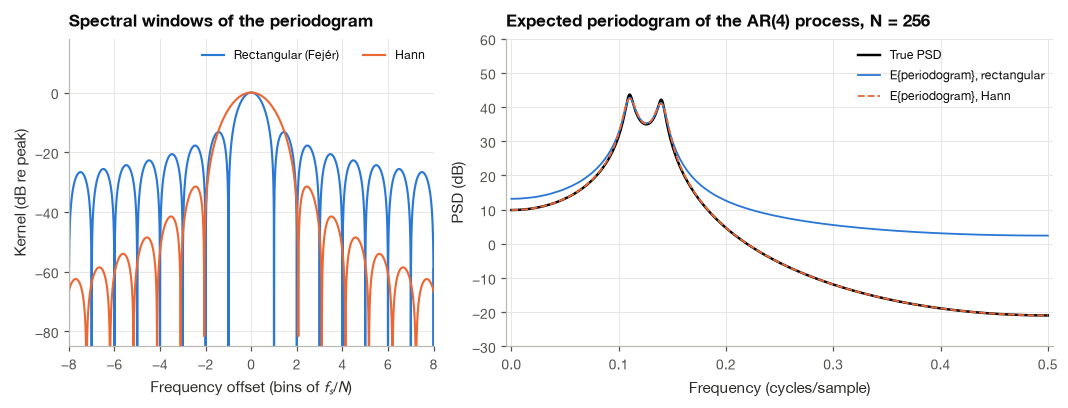

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.6), gridspec_kw={"width_ratios": [1, 1.5]})
N_k = 32
Om = np.linspace(-np.pi, np.pi, 4001)
for win, col, lab in [("boxcar", C[0], "Rectangular (Fejér)"), ("hann", C[1], "Hann")]:
    w = signal.get_window(win, N_k, fftbins=False)
    _, W = signal.freqz(w, worN=Om)
    K = np.abs(W) ** 2 / (N_k * np.mean(w**2))
    axes[0].plot(Om * N_k / (2 * np.pi), 10 * np.log10(K / K.max() + 1e-12), color=col, label=lab)
axes[0].set(xlim=(-8, 8), ylim=(-85, 18), xlabel=r"Frequency offset (bins of $f_s/N$)",
            ylabel="Kernel (dB re peak)", title="Spectral windows of the periodogram")
axes[0].legend(loc="upper right", fontsize=8, ncols=2)

axes[1].plot(f_norm, dB(S_true), color="k", lw=1.6, label="True PSD")
axes[1].plot(f_norm, dB(E_rect), color=C[0], lw=1.2, label="E{periodogram}, rectangular")
axes[1].plot(f_norm, dB(E_hann), color=C[1], lw=1.2, ls="--", label="E{periodogram}, Hann")
axes[1].set(xlabel="Frequency (cycles/sample)", ylabel="PSD (dB)", ylim=(-30, 60),
            title="Expected periodogram of the AR(4) process, N = 256")
axes[1].legend(loc="upper right", fontsize=8)
plt.show()

The left panel compares the two spectral windows, plotted for $N = 32$ so that the individual lobes are visible: the Hann main lobe is twice as wide, but its sidelobes start almost 20 dB lower and fall away much faster. The right panel shows the consequence. With the rectangular window, power leaking from the twin peaks through the Fejér sidelobes holds the expected periodogram above the truth over the whole upper part of the band, by about 23 dB at the Nyquist frequency. This is a bias of the *expected value*, so no amount of averaging could recover the true spectrum there. The Hann taper follows the true PSD over its full 65 dB range, and its wider main lobe costs little here because $N = 256$ is long enough to resolve the two peaks. I taper by default for this reason and only use the rectangular window when resolution is everything and the dynamic range is small.

(sec-7-3-3)=
## 7.3.3 Variance: Why the Periodogram Does Not Settle Down

Bias shrinks as $N$ grows. Variance does not, and this is the more surprising defect. The cleanest way to see it is to work out the distribution of the periodogram for Gaussian white noise with variance $\sigma^2$, whose true PSD is the constant $\sigma^2$ in radians per sample.

**Step 1: split one DFT coefficient into real and imaginary parts.** For a bin $0 < k < N/2$,

$$
X[k] = \sum_{n=0}^{N-1} x[n]\cos\!\left(\frac{2\pi k n}{N}\right) - j\sum_{n=0}^{N-1} x[n]\sin\!\left(\frac{2\pi k n}{N}\right) = A_k - jB_k .
$$

Both $A_k$ and $B_k$ are weighted sums of independent Gaussian samples, so they are Gaussian with zero mean.

**Step 2: compute their variances and covariance.** Because $\mathbb{E}\{x[n]x[m]\} = \sigma^2\delta[n - m]$, only the diagonal terms of the double sum survive:

$$
\mathbb{E}\{A_k^2\} = \sigma^2\sum_{n=0}^{N-1}\cos^2\!\left(\frac{2\pi k n}{N}\right) = \sigma^2\sum_{n=0}^{N-1}\frac{1 + \cos(4\pi k n/N)}{2} = \frac{N\sigma^2}{2}.
$$

The cosine sum vanishes because $2k$ is not a multiple of $N$ (it is a sum of equally spaced points on the unit circle, as in [Section 2.1.5](../ch02_math_toolkit/01_complex_numbers.ipynb#sec-2-1-5)). In the same way $\mathbb{E}\{B_k^2\} = N\sigma^2/2$, and $\mathbb{E}\{A_kB_k\} = \sigma^2\sum_n \cos\sin = \tfrac{\sigma^2}{2}\sum_n \sin(4\pi kn/N) = 0$. Uncorrelated Gaussian variables are independent.

**Step 3: identify the distribution.** Writing $A_k = \sqrt{N\sigma^2/2}\,Z_1$ and $B_k = \sqrt{N\sigma^2/2}\,Z_2$ with $Z_1, Z_2$ independent standard normal variables,

$$
\hat{S}_P(e^{j\Omega_k}) = \frac{A_k^2 + B_k^2}{N} = \frac{\sigma^2}{2}\left(Z_1^2 + Z_2^2\right) = \sigma^2\,\frac{\chi^2_2}{2},
$$

where $\chi^2_2$ denotes a chi-squared variable with two degrees of freedom, which has mean 2 and variance 4. The periodogram value therefore has mean $\sigma^2$, as it should, and variance $\sigma^4$. **Its standard deviation equals its mean, whatever the value of $N$.** The same orthogonality argument shows that values at different bins are uncorrelated, which is why a periodogram looks like independent noise from bin to bin.

For a colored Gaussian process the same result holds approximately once $N$ is large compared with the correlation time {cite:p}`percival1993,stoica2005`:

(eq-7-28)=
\begin{equation*}
\hat{S}_P(f) \approx S_x(f)\,\frac{\chi^2_2}{2}, \qquad \operatorname{Var}\{\hat{S}_P(f)\} \approx S_x^2(f), \qquad 0 < f < f_s/2 . \tag{7.28}
\end{equation*}

The $\chi^2_2/2$ distribution is the unit exponential distribution, and its quantiles make the problem concrete. The probability that a periodogram value falls below one tenth of the truth is $1 - e^{-0.1} \approx 9.5\%$, and a central 95% interval for a single value runs from $0.025\,S_x$ to $3.7\,S_x$, a range of about 22 dB. An estimator that is not guaranteed to land within an order of magnitude of the truth is of little use for measuring alpha power. In statistical language the periodogram is **inconsistent**: more data gives more frequency bins, not more accurate ones. Equation [(7.24)](#eq-7-24) explains why: the extra samples are spent estimating more lags of the autocorrelation, each one poorly, instead of estimating a fixed number of lags well.

In [6]:
n_rec = 2000
for N in [64, 256, 1024, 4096]:
    x = rng.normal(0, 1, size=(n_rec, N))
    P = np.abs(np.fft.rfft(x, axis=1)[:, 1:N // 2]) ** 2 / N        # radians-per-sample scaling
    print(f"N = {N:5d}: mean = {P.mean():.3f}, std = {P.std():.3f}, "
          f"P(value < 0.1 x truth) = {np.mean(P < 0.1):.3f}")

N =    64: mean = 1.006, std = 1.008, P(value < 0.1 x truth) = 0.095
N =   256: mean = 1.000, std = 0.997, P(value < 0.1 x truth) = 0.095
N =  1024: mean = 0.999, std = 0.999, P(value < 0.1 x truth) = 0.095
N =  4096: mean = 0.999, std = 1.000, P(value < 0.1 x truth) = 0.095


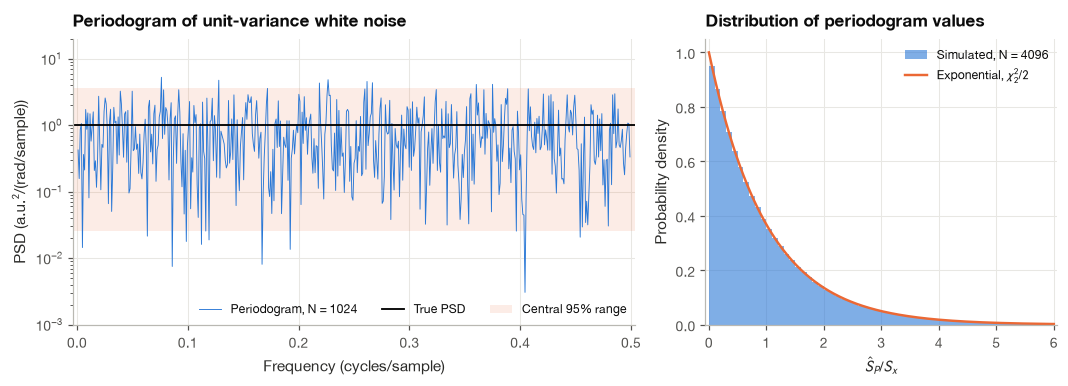

In [7]:
N = 1024
x = rng.normal(0, 1, N)
P1 = np.abs(np.fft.rfft(x)[1:N // 2]) ** 2 / N
fk = np.arange(1, N // 2) / N
lo, hi = stats.chi2.ppf([0.025, 0.975], 2) / 2

fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.4), gridspec_kw={"width_ratios": [1.6, 1]})
axes[0].plot(fk, P1, color=C[0], lw=0.6, label="Periodogram, N = 1024")
axes[0].axhline(1, color="k", lw=1.2, label="True PSD")
axes[0].axhspan(lo, hi, color=C[1], alpha=0.12, lw=0, label="Central 95% range")
axes[0].set(yscale="log", ylim=(1e-3, 20), xlabel="Frequency (cycles/sample)",
            ylabel="PSD (a.u.$^2$/(rad/sample))", title="Periodogram of unit-variance white noise")
axes[0].legend(loc="lower right", fontsize=8, ncols=3)

xs = np.linspace(0, 6, 300)
axes[1].hist(P.ravel(), bins=np.linspace(0, 6, 61), density=True, color=C[0], alpha=0.6,
             label="Simulated, N = 4096")
axes[1].plot(xs, np.exp(-xs), color=C[1], lw=1.6, label=r"Exponential, $\chi^2_2/2$")
axes[1].set(xlabel=r"$\hat{S}_P / S_x$", ylabel="Probability density",
            title="Distribution of periodogram values")
axes[1].legend(loc="upper right", fontsize=8)
plt.show()

(sec-7-3-4)=
## 7.3.4 Bartlett's Method: Averaging Segments

If one periodogram has a standard deviation equal to its mean, the average of $K$ independent periodograms has a standard deviation $1/\sqrt{K}$ times its mean. We saw this in [Section 7.2.7](02_power_spectral_density.ipynb#sec-7-2-7) by averaging over independent realizations. {cite:t}`bartlett1948` pointed out that a single long record can supply the realizations itself. Cut the $N$ samples into $K$ non-overlapping segments of length $L$, $x_i[n] = x[n + iL]$ for $0 \le n \le L - 1$ and $i = 0, \ldots, K-1$, compute the periodogram of each segment, and average:

(eq-7-29)=
\begin{equation*}
\hat{S}_B(e^{j\Omega}) = \frac{1}{K}\sum_{i=0}^{K-1}\frac{1}{L}\left|\sum_{n=0}^{L-1} x_i[n]\,e^{-j\Omega n}\right|^2 . \tag{7.29}
\end{equation*}

Its two moments follow from what we already know.

**Mean.** Each segment is a record of length $L$ from the same stationary process, so each segment periodogram has the expected value [(7.26)](#eq-7-26) with $F_L$ in place of $F_N$. Averaging does not change the mean. The resolution is now about $f_s/L$ instead of $f_s/N$, coarser by the factor $K$.

**Variance.** If the segments are long compared with the correlation time of the process, their periodograms are nearly independent, and by [(7.28)](#eq-7-28)

$$
\operatorname{Var}\{\hat{S}_B(f)\} \approx \frac{1}{K}\,S_x^2(f).
$$

For a record of fixed duration $T = N/f_s$, the product of the two quantities we care about is therefore fixed:

(eq-7-30)=
\begin{equation*}
\underbrace{\frac{f_s}{L}}_{\text{resolution (Hz)}} \times \underbrace{\frac{\operatorname{Var}\{\hat{S}_B\}}{S_x^2}}_{\approx 1/K} \approx \frac{f_s}{L}\cdot\frac{L}{N} = \frac{1}{T}. \tag{7.30}
\end{equation*}

Halving the segment length halves the variance and doubles the resolution bandwidth. Only a longer recording improves both at once. I find [(7.30)](#eq-7-30) the single most useful rule for planning a spectral analysis: five minutes of EEG analyzed with 0.5 Hz resolution supports a variance reduction by a factor of about 150, and one minute supports only 30.

(sec-7-3-5)=
## 7.3.5 Welch's Method: Windowed, Overlapping Segments

{cite:t}`welch1967` made two changes to Bartlett's method that together define the estimator used by almost every physiological toolbox. Each segment is multiplied by a taper $w[n]$ to control leakage, and the segments **overlap**, each starting $D$ samples after the previous one with $D < L$. With $K = \lfloor (N - L)/D \rfloor + 1$ segments $x_i[n] = x[n + iD]$, the two-sided Welch estimate in units²/Hz is

(eq-7-31)=
\begin{equation*}
\hat{S}_W(f) = \frac{1}{K}\sum_{i=0}^{K-1}\frac{1}{f_s\sum_{n=0}^{L-1} w^2[n]}\left|\sum_{n=0}^{L-1} w[n]\,x_i[n]\,e^{-j2\pi f n/f_s}\right|^2 , \tag{7.31}
\end{equation*}

which is the average of $K$ modified periodograms [(7.27)](#eq-7-27), converted to hertz. The one-sided version doubles every bin except DC and Nyquist, as in [(7.23)](#eq-7-23).

Why overlap? A taper weights the middle of each segment heavily and its ends lightly, so with non-overlapping segments the samples near the segment boundaries hardly contribute. Overlapping segments by half puts every sample near the middle of some segment. Overlapping segments are correlated, so doubling their number does not halve the variance, but for the Hann window at 50% overlap the correlation is small and the gain is close to the full factor of two, as we check below. In my experience 50% overlap with a Hann window is the right default; more overlap costs computation and buys almost nothing.

### Density versus spectrum scaling

The normalization in [(7.31)](#eq-7-31) makes the area under the estimate equal to the power, which is right for broadband signals such as EEG background or noise. A **sinusoid** is different: its power sits at a single frequency, and what we usually want to read off the plot is that power, $A^2/2$ for amplitude $A$. If the sinusoid falls on a bin, its windowed DFT peak has magnitude $\frac{A}{2}\sum_n w[n]$, so the one-sided estimate shows the line at

$$
2\cdot\frac{(A/2)^2\,\big(\sum_n w[n]\big)^2}{f_s\sum_n w^2[n]} = \frac{A^2/2}{B_e}, \qquad B_e = f_s\,\frac{\sum_n w^2[n]}{\big(\sum_n w[n]\big)^2},
$$

where $B_e$ is the **equivalent noise bandwidth** of the window in hertz (1.5 bins, i.e. $1.5f_s/L$, for the Hann window). The height of a line in a density plot therefore depends on the segment length, which is confusing. `scipy.signal.welch` offers `scaling="spectrum"`, which replaces $f_s\sum w^2$ by $(\sum w)^2$ in [(7.31)](#eq-7-31) and reports units² instead of units²/Hz. Then a line reads directly as its power $A^2/2$, while a broadband noise floor moves with $L$. The rule I follow is simple: use density for anything broadband and whenever you integrate over a band, and use spectrum scaling only to read the power of isolated lines such as mains interference.

### Implementation from scratch

The implementation follows [(7.31)](#eq-7-31) line by line. To match SciPy's defaults we remove the mean of each segment (`detrend="constant"`) and use the periodic Hann window that `get_window` returns.

In [8]:
def welch_psd(x, fs, nperseg, noverlap=None, window="hann", scaling="density"):
    """Welch's method, equation (12.31): averaged, windowed, overlapping periodograms (one-sided)."""
    noverlap = nperseg // 2 if noverlap is None else noverlap
    w = signal.get_window(window, nperseg)
    step = nperseg - noverlap
    starts = np.arange(0, x.size - nperseg + 1, step)
    segs = np.stack([x[s:s + nperseg] for s in starts])
    segs = segs - segs.mean(axis=1, keepdims=True)
    norm = fs * np.sum(w**2) if scaling == "density" else np.sum(w) ** 2
    P = np.mean(np.abs(np.fft.rfft(segs * w, axis=1)) ** 2, axis=0) / norm
    P[1:(nperseg + 1) // 2] *= 2
    return np.fft.rfftfreq(nperseg, 1 / fs), P, len(starts)


fs = 360.0
t = np.arange(0, 60, 1 / fs)
x = 0.2 * np.cos(2 * np.pi * 60 * t) + rng.normal(0, 0.05, t.size)   # 0.2 mV mains + noise
for L in [360, 1440]:
    for scaling in ["density", "spectrum"]:
        f, P, K = welch_psd(x, fs, L, scaling=scaling)
        _, P_sp = signal.welch(x, fs=fs, nperseg=L, scaling=scaling)
        unit = "mV^2/Hz" if scaling == "density" else "mV^2"
        print(f"L = {L:4d}, {scaling:8s}: K = {K:3d}, line at 60 Hz = {P[f == 60][0]:.4f} {unit}, "
              f"floor = {np.median(P):.2e} {unit}, max rel. diff to scipy = "
              f"{np.max(np.abs(P - P_sp) / P_sp):.0e}")

L =  360, density : K = 119, line at 60 Hz = 0.0134 mV^2/Hz, floor = 1.39e-05 mV^2/Hz, max rel. diff to scipy = 1e-15
L =  360, spectrum: K = 119, line at 60 Hz = 0.0200 mV^2, floor = 2.09e-05 mV^2, max rel. diff to scipy = 2e-15
L = 1440, density : K =  29, line at 60 Hz = 0.0534 mV^2/Hz, floor = 1.37e-05 mV^2/Hz, max rel. diff to scipy = 2e-15
L = 1440, spectrum: K =  29, line at 60 Hz = 0.0200 mV^2, floor = 5.13e-06 mV^2, max rel. diff to scipy = 4e-15


Our function agrees with SciPy to rounding error. The output also shows the two scalings at work. With spectrum scaling the 60 Hz line reads $0.02$ mV², which is $A^2/2$ for $A = 0.2$ mV, at both segment lengths, while the noise floor drops by a factor of four when $L$ quadruples. With density scaling it is the other way round: the floor stays at the white-noise level $2\sigma^2/f_s \approx 1.4\times 10^{-5}$ mV²/Hz, and the line grows with $L$ because $B_e$ shrinks.

### How much does overlap help?

For Gaussian data the Welch estimate is approximately $S_x\,\chi^2_\nu/\nu$, a scaled chi-squared variable with $\nu$ **equivalent degrees of freedom**. For $K$ non-overlapping segments $\nu = 2K$. With overlap, the correlation between the periodograms of segments $m$ steps apart is approximately $\rho^2(m)$, where $\rho(m) = \sum_n w[n]w[n + mD] / \sum_n w^2[n]$ is the normalized overlap of the windows, and the degrees of freedom become {cite:p}`welch1967,percival1993`

(eq-7-32)=
\begin{equation*}
\nu \approx \frac{2K}{1 + 2\sum_{m=1}^{K-1}\left(1 - \frac{m}{K}\right)\rho^2(m)}, \qquad \operatorname{Var}\{\hat{S}_W(f)\} \approx \frac{2}{\nu}\,S_x^2(f). \tag{7.32}
\end{equation*}

In [9]:
def welch_dof(window, nperseg, noverlap, N):
    """Equivalent degrees of freedom of a Welch estimate, equation (12.32)."""
    w = signal.get_window(window, nperseg)
    D = nperseg - noverlap
    K = (N - nperseg) // D + 1
    rho = lambda m: np.sum(w[m * D:] * w[:nperseg - m * D]) / np.sum(w**2) if m * D < nperseg else 0.0
    return 2 * K / (1 + 2 * sum((1 - m / K) * rho(m) ** 2 for m in range(1, K))), K


N, L = 8192, 256
rows = []
for overlap in [0.0, 0.25, 0.5, 0.75]:
    nu, K = welch_dof("hann", L, int(overlap * L), N)
    x = rng.normal(0, 1, size=(400, N))
    _, P = signal.welch(x, fs=1.0, nperseg=L, noverlap=int(overlap * L), axis=-1)
    rel_var = np.var(P[:, 5:-5] / 2.0)            # true one-sided PSD of unit white noise is 2
    rows.append({"overlap": f"{overlap:.0%}", "segments K": K, "dof nu, eq. (12.32)": round(nu, 1),
                 "predicted var 2/nu": 2 / nu, "simulated var": rel_var})
print(pd.DataFrame(rows).round(4).to_string(index=False))

overlap  segments K  dof nu, eq. (12.32)  predicted var 2/nu  simulated var
     0%          32                 64.0              0.0312         0.0313
    25%          42                 84.0              0.0238         0.0238
    50%          63                119.5              0.0167         0.0166
    75%         125                130.4              0.0153         0.0153


(sec-7-3-6)=
## 7.3.6 The Bias–Variance Trade-Off in Practice

The segment length $L$ is the main decision in a Welch analysis, and [(7.30)](#eq-7-30) says it cannot be made without giving something up. The next figure shows one realization of $N = 4096$ samples of the AR(4) process analyzed with three segment lengths.

In [10]:
N = 4096
w_ar = rng.normal(0, 1, size=(300, N + 2000))
x_ar = signal.lfilter([1.0], a_ar4, w_ar, axis=1)[:, 2000:]      # 300 realizations, burn-in removed

seg_lengths = [32, 64, 128, 256, 512, 1024, 2048]
results = {}
for L in seg_lengths:
    f_w, P = signal.welch(x_ar, fs=1.0, nperseg=L, axis=-1)
    S = 2 * ar_psd(f_w, a_ar4)                                   # one-sided truth
    keep = (f_w > 0) & (f_w < 0.5)
    bias2 = np.mean(((P.mean(axis=0) - S) / S)[keep] ** 2)
    var = np.mean((P.var(axis=0) / S**2)[keep])
    results[L] = (f_w, P[0], S, bias2, var)
print(pd.DataFrame({"L": seg_lengths,
                    "rel. bias^2": [results[L][3] for L in seg_lengths],
                    "rel. variance": [results[L][4] for L in seg_lengths],
                    "rel. MSE": [results[L][3] + results[L][4] for L in seg_lengths]}).round(3).to_string(index=False))

   L  rel. bias^2  rel. variance  rel. MSE
  32       24.785          0.353    25.139
  64        1.578          0.045     1.623
 128        0.078          0.022     0.100
 256        0.005          0.035     0.040
 512        0.001          0.070     0.071
1024        0.001          0.149     0.150
2048        0.001          0.344     0.346


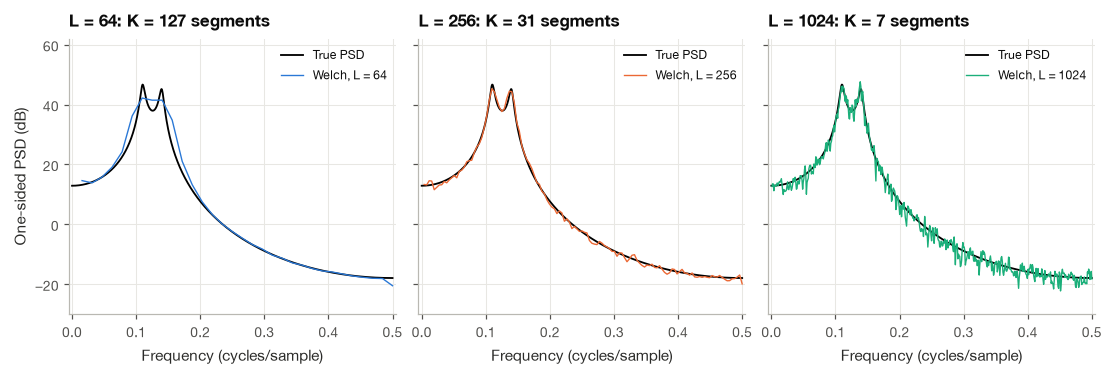

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.3), sharey=True)
f_fine = np.linspace(0, 0.5, 1001)
for ax, L, col in zip(axes, [64, 256, 1024], [C[0], C[1], C[2]]):
    f_w, P0, S, _, _ = results[L]
    ax.plot(f_fine, dB(2 * ar_psd(f_fine, a_ar4)), color="k", lw=1.2, label="True PSD")
    ax.plot(f_w[1:], dB(P0[1:]), color=col, lw=0.9, label=f"Welch, L = {L}")
    ax.set(xlabel="Frequency (cycles/sample)", title=f"L = {L}: K = {(N - L) // (L // 2) + 1} segments")
    ax.legend(loc="upper right", fontsize=8)
axes[0].set(ylabel="One-sided PSD (dB)", ylim=(-30, 62))
plt.show()

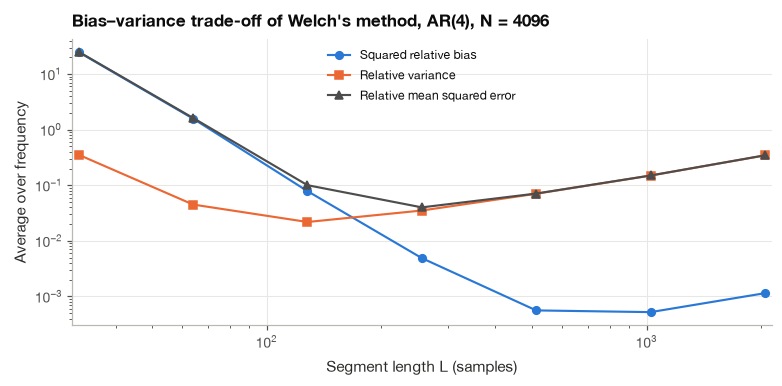

In [12]:
fig, ax = plt.subplots(figsize=(7, 3.4))
b2 = np.array([results[L][3] for L in seg_lengths])
v = np.array([results[L][4] for L in seg_lengths])
ax.loglog(seg_lengths, b2, "o-", color=C[0], label="Squared relative bias")
ax.loglog(seg_lengths, v, "s-", color=C[1], label="Relative variance")
ax.loglog(seg_lengths, b2 + v, "^-", color="0.3", label="Relative mean squared error")
ax.set(xlabel="Segment length L (samples)", ylabel="Average over frequency",
       title="Bias–variance trade-off of Welch's method, AR(4), N = 4096")
ax.legend(loc="upper center", fontsize=8)
plt.show()

With $L = 64$ the estimate is smooth, but the two peaks have merged into one flat-topped hump that is several decibels too low, and its skirts are too wide: low variance, large bias. With $L = 1024$ the peaks are resolved and the deep part of the spectrum is followed, but the curve scatters by several decibels from bin to bin: small bias, large variance. $L = 256$ sits in between and is the best of the three. The Monte Carlo summary over 300 realizations makes the trade-off quantitative. The squared relative bias falls by four orders of magnitude between $L = 32$ and $L = 512$, because the two narrow peaks need a fine resolution. From $L = 128$ upward the relative variance doubles each time $L$ doubles, as [(7.30)](#eq-7-30) predicts. (At the shortest lengths the variance rises again, for a reason that is worth understanding: the variance is proportional to the square of the expected value, so wherever leakage inflates the expected value, it inflates the variance too.) The mean squared error is smallest at $L = 256$, where it is 0.04, an RMS error of about 20% of the true PSD.

There is no universal best $L$; it depends on how sharp the features of the true spectrum are, which is exactly what we do not know in advance. In practice I choose $L$ from the physiology: the narrowest feature I need to resolve sets the resolution bandwidth, which is $B_e = 1.5 f_s/L$ for a Hann window, and that sets $L$. I then check that the record supplies enough segments, ideally more than about 10, for a stable estimate.

(sec-7-3-7)=
## 7.3.7 Confidence Intervals

Equation [(7.32)](#eq-7-32) does more than predict the variance. If $\nu\hat{S}_W(f)/S_x(f)$ follows a $\chi^2_\nu$ distribution, we can bracket it between two quantiles and invert the inequality to obtain an interval for the unknown $S_x(f)$.

**Step 1: bracket the pivot.** Let $q_{\alpha/2}$ and $q_{1-\alpha/2}$ be the lower and upper $\alpha/2$ quantiles of $\chi^2_\nu$. Then

$$
P\left(q_{\alpha/2} \le \frac{\nu\,\hat{S}_W(f)}{S_x(f)} \le q_{1-\alpha/2}\right) = 1 - \alpha .
$$

**Step 2: solve for $S_x(f)$.** All quantities are positive, so taking reciprocals reverses the inequalities and multiplying by $\nu\hat{S}_W(f)$ gives

(eq-7-33)=
\begin{equation*}
\frac{\nu\,\hat{S}_W(f)}{q_{1-\alpha/2}} \;\le\; S_x(f) \;\le\; \frac{\nu\,\hat{S}_W(f)}{q_{\alpha/2}} \quad\text{with probability } 1 - \alpha. \tag{7.33}
\end{equation*}

**Step 3: read it in decibels.** Taking $10\log_{10}$ of [(7.33)](#eq-7-33), the interval is $\hat{S}_W$ in dB plus the constants $10\log_{10}(\nu/q_{1-\alpha/2})$ and $10\log_{10}(\nu/q_{\alpha/2})$. On a logarithmic axis the confidence band has the *same width at every frequency*, which is one good reason to plot PSDs in dB.

The interval accounts only for variance. Where the estimate is biased, near sharp peaks or in leakage-dominated regions, the true PSD can lie outside it far more often than $\alpha$ suggests. We check the coverage on the AR(4) realizations.

In [13]:
def welch_ci(P, nu, alpha=0.05):
    """Chi-squared confidence interval for a Welch estimate, equation (12.33)."""
    q_lo, q_hi = stats.chi2.ppf([alpha / 2, 1 - alpha / 2], nu)
    return nu * P / q_hi, nu * P / q_lo


for L in [64, 256, 1024]:
    f_w, P = signal.welch(x_ar, fs=1.0, nperseg=L, axis=-1)
    nu, K = welch_dof("hann", L, L // 2, N)
    lo, hi = welch_ci(P, nu)
    S = 2 * ar_psd(f_w, a_ar4)
    keep = (f_w > 0) & (f_w < 0.5)
    inside = ((lo <= S) & (S <= hi))[:, keep]
    near_peaks = keep & (f_w > 0.08) & (f_w < 0.17)
    away = keep & ~near_peaks
    print(f"L = {L:4d}: nu = {nu:5.1f}, 95% CI width = {dB(hi[0, 5] / lo[0, 5]):4.1f} dB, coverage: "
          f"all {inside.mean():.3f}, near peaks {((lo <= S) & (S <= hi))[:, near_peaks].mean():.3f}, "
          f"elsewhere {((lo <= S) & (S <= hi))[:, away].mean():.3f}")

L =   64: nu = 240.7, 95% CI width =  1.6 dB, coverage: all 0.615, near peaks 0.000, elsewhere 0.733
L =  256: nu =  58.8, 95% CI width =  3.2 dB, coverage: all 0.935, near peaks 0.857, elsewhere 0.952
L = 1024: nu =  13.4, 95% CI width =  6.8 dB, coverage: all 0.951, near peaks 0.951, elsewhere 0.951


With 1024-sample segments only about 13 degrees of freedom are left and the 95% interval is 6.8 dB wide, but it contains the true PSD 95% of the time at every frequency, exactly as promised, because the bias is negligible. With 256-sample segments the interval narrows to 3.2 dB and the coverage is still correct away from the peaks, but it drops to 86% near them, where the smoothing bias starts to matter. With 64-sample segments the interval is a narrow 1.6 dB and almost useless: it *never* contains the truth near the peaks, and only 73% of the time elsewhere. A narrow confidence band around a biased estimate is a confident wrong answer. Before trusting a band, I check that the segment length resolves the features of interest, for example by comparing two values of $L$ and making sure the spectrum does not change shape.

(sec-7-3-8)=
## 7.3.8 Applied Example: Spectra of a Real ECG and EEG

We now put the estimator to work on two real recordings. The ECG example shows how the choice of $L$ changes what a spectrum of a quasi-periodic signal reveals. The EEG example measures a physiological effect, the increase of occipital alpha power when the eyes close, and asks whether it is larger than the uncertainty of the estimate.

### Step 1: Load five minutes of ECG

We use the MLII lead of MIT-BIH record 100 {cite:p}`moody2001,goldberger2000`, a clean recording in sinus rhythm, and the beat annotations to compute the mean heart rate independently of the spectrum.

In [14]:
fs_ecg = 360
rec = wfdb.rdrecord("../data/mitdb/100", sampto=300 * fs_ecg, channels=[0])
ecg = rec.p_signal[:, 0]
ann = wfdb.rdann("../data/mitdb/100", "atr", sampto=300 * fs_ecg)
beats = ann.sample[np.isin(ann.symbol, ["N", "A", "V"])]
rr = np.diff(beats) / fs_ecg
print(f"{ecg.size / fs_ecg:.0f} s of lead {rec.sig_name[0]}, {beats.size} beats, "
      f"mean heart rate {60 / rr.mean():.1f} bpm ({1 / rr.mean():.3f} Hz), RR SD {1000 * rr.std():.0f} ms")

300 s of lead MLII, 371 beats, mean heart rate 74.2 bpm (1.237 Hz), RR SD 39 ms


### Step 2: Estimate the PSD with short and long segments

A 2 s segment holds two or three beats and gives a resolution of about 0.75 Hz (the Hann equivalent noise bandwidth, $1.5 f_s/L$); a 20 s segment holds about 25 beats and resolves 0.075 Hz.

In [15]:
psd_ecg = {}
for seg_s in [2, 20]:
    L = seg_s * fs_ecg
    f_e, P_e = signal.welch(ecg, fs=fs_ecg, nperseg=L)
    nu, K = welch_dof("hann", L, L // 2, ecg.size)
    psd_ecg[seg_s] = (f_e, P_e, nu)
    print(f"L = {seg_s:2d} s: K = {K:3d} segments, nu = {nu:5.1f}, resolution (B_e) = {1.5 / seg_s:.3f} Hz")

f_e, P_e, _ = psd_ecg[20]
search = (f_e > 0.8) & (f_e < 2.0)
f_peak = f_e[search][np.argmax(P_e[search])]
print(f"Spectral peak between 0.8 and 2 Hz: {f_peak:.3f} Hz = {60 * f_peak:.1f} bpm")

L =  2 s: K = 299 segments, nu = 566.6, resolution (B_e) = 0.750 Hz
L = 20 s: K =  29 segments, nu =  55.0, resolution (B_e) = 0.075 Hz
Spectral peak between 0.8 and 2 Hz: 1.250 Hz = 75.0 bpm


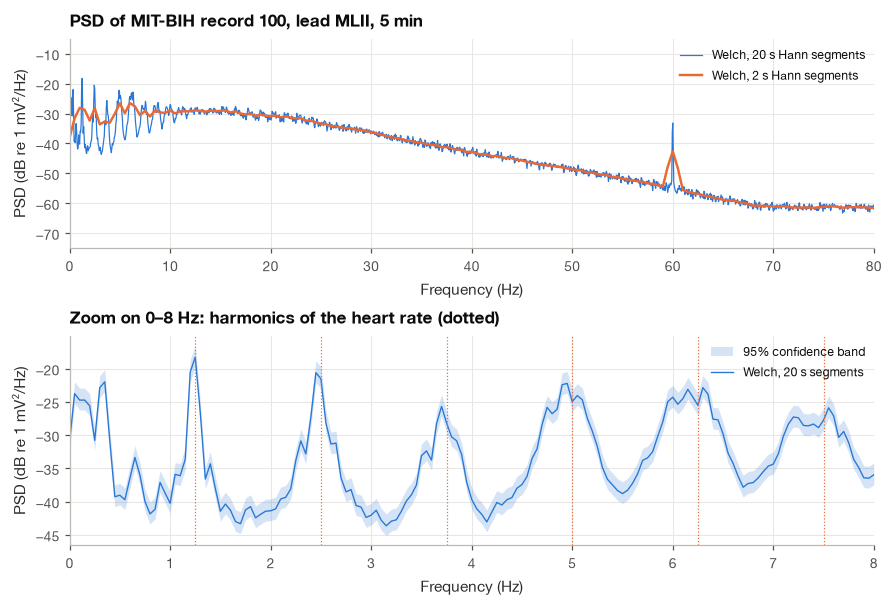

In [16]:
fig, axes = plt.subplots(2, 1, figsize=(8, 5.4))
for seg_s, col, lw in [(20, C[0], 0.8), (2, C[1], 1.6)]:
    f_e, P_e, _ = psd_ecg[seg_s]
    axes[0].plot(f_e, dB(P_e), color=col, lw=lw, label=f"Welch, {seg_s} s Hann segments")
axes[0].set(xlim=(0, 80), ylim=(-75, -5), xlabel="Frequency (Hz)", ylabel="PSD (dB re 1 mV$^2$/Hz)",
            title="PSD of MIT-BIH record 100, lead MLII, 5 min")
axes[0].legend(loc="upper right", fontsize=8)

f_e, P_e, nu = psd_ecg[20]
lo, hi = welch_ci(P_e, nu)
m = f_e <= 8
axes[1].fill_between(f_e[m], dB(lo[m]), dB(hi[m]), color=C[0], alpha=0.2, lw=0, label="95% confidence band")
axes[1].plot(f_e[m], dB(P_e[m]), color=C[0], lw=0.9, label="Welch, 20 s segments")
for h_ in range(1, 7):
    axes[1].axvline(h_ * f_peak, color=C[1], lw=0.8, ls=":")
axes[1].set(xlim=(0, 8), xlabel="Frequency (Hz)", ylabel="PSD (dB re 1 mV$^2$/Hz)",
            title="Zoom on 0–8 Hz: harmonics of the heart rate (dotted)")
axes[1].legend(loc="upper right", fontsize=8)
plt.show()

### Step 3: Interpret the ECG spectrum

The two estimates describe the same signal at two levels of detail. With 2 s segments the spectrum is close to a smooth envelope: the density is roughly flat between 1 and 15 Hz, where the QRS complex and the slower waves put their energy, and then falls by about 25 dB toward 58 Hz. This envelope is what matters for filter design, and it is why ECG monitoring filters can cut at about 40 Hz without losing much of the waveform. A narrow line stands out at exactly 60 Hz: power-line interference from the recording environment (the MIT-BIH recordings were made in Boston, where the mains frequency is 60 Hz), which we learn to remove in Section 15.4. With 20 s segments the low-frequency part of the envelope breaks up into a comb of narrow peaks at multiples of the heart rate. The ECG is nearly periodic, so by the Fourier series of [Chapter 5](../ch07_fourier_series/index.md) its power concentrates at harmonics of the beat frequency. The first peak sits at 1.250 Hz, the nearest frequency bin to the 1.237 Hz heart rate computed from the annotations. The harmonics broaden at higher orders because the beat-to-beat variation of the RR interval (39 ms standard deviation here) smears the $h$-th harmonic over $h$ times the range of instantaneous heart rates. The peak near 0.3 Hz below the fundamental is probably respiration, which moves the baseline and modulates the amplitude of the ECG at the breathing rate. Section 10.5 looks at this structure in more detail. Neither picture is wrong. The segment length decides which question the spectrum answers.

### Step 4: Load eyes-open and eyes-closed EEG

The EEG Motor Movement/Imagery Database {cite:p}`schalk2004,goldberger2000` begins each subject's session with one minute of rest with the eyes open (run 1) and one minute with the eyes closed (run 2). We take the occipital channel O1, where the alpha rhythm is strongest, and convert it to µV.

In [17]:
eeg = {}
for run, label in [("R01", "eyes open"), ("R02", "eyes closed")]:
    raw = mne.io.read_raw_edf(f"../data/eegmmidb/S001{run}.edf", preload=True)
    mne.datasets.eegbci.standardize(raw)
    eeg[label] = raw.get_data(picks=["O1"])[0] * 1e6
    fs_eeg = raw.info["sfreq"]
    print(f"{label:11s}: {eeg[label].size / fs_eeg:.1f} s at {fs_eeg:.0f} Hz, RMS {eeg[label].std():.1f} uV")

eyes open  : 61.0 s at 160 Hz, RMS 52.3 uV
eyes closed: 61.0 s at 160 Hz, RMS 78.5 uV


### Step 5: Welch PSDs with confidence bands

Alpha activity occupies roughly 8–13 Hz, so a resolution of about 1 Hz is enough. I use 2 s Hann segments with 50% overlap, which gives $B_e = 0.75$ Hz and about 60 segments per minute of data.

In [18]:
L_eeg = int(2 * fs_eeg)
psd_eeg = {}
for label, x in eeg.items():
    f_g, P_g = signal.welch(x, fs=fs_eeg, nperseg=L_eeg)
    nu, K = welch_dof("hann", L_eeg, L_eeg // 2, x.size)
    psd_eeg[label] = (P_g, *welch_ci(P_g, nu))
    print(f"{label:11s}: K = {K} segments, nu = {nu:.0f}, 95% CI from "
          f"{dB(psd_eeg[label][1][10] / P_g[10]):+.1f} dB to {dB(psd_eeg[label][2][10] / P_g[10]):+.1f} dB")

eyes open  : K = 60 segments, nu = 114, 95% CI from -1.1 dB to +1.2 dB
eyes closed: K = 60 segments, nu = 114, 95% CI from -1.1 dB to +1.2 dB


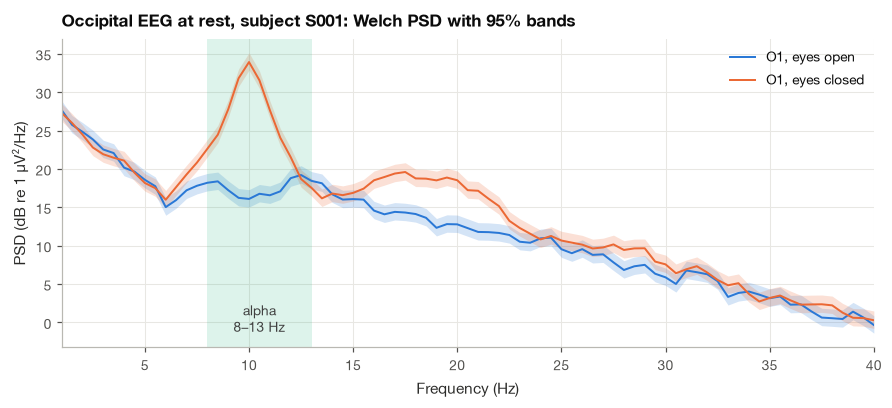

In [19]:
fig, ax = plt.subplots(figsize=(8, 3.6))
m = (f_g >= 1) & (f_g <= 40)
for (label, (P_g, lo, hi)), col in zip(psd_eeg.items(), [C[0], C[1]]):
    ax.fill_between(f_g[m], dB(lo[m]), dB(hi[m]), color=col, alpha=0.2, lw=0)
    ax.plot(f_g[m], dB(P_g[m]), color=col, lw=1.3, label=f"O1, {label}")
ax.axvspan(8, 13, color=C[2], alpha=0.15, lw=0)
ax.text(10.5, ax.get_ylim()[0] + 2, "alpha\n8–13 Hz", ha="center", fontsize=9, color="0.25")
ax.set(xlim=(1, 40), xlabel="Frequency (Hz)", ylabel="PSD (dB re 1 µV$^2$/Hz)",
       title="Occipital EEG at rest, subject S001: Welch PSD with 95% bands")
ax.legend(loc="upper right")
plt.show()

### Step 6: Band power

Band power is the area under the one-sided density over the band, the same integral we used in [Section 7.2.8](02_power_spectral_density.ipynb#sec-7-2-8). I report it in absolute terms (µV²) and relative to the total power between 1 and 40 Hz, which removes differences in overall amplitude between recordings.

In [20]:
def band_power(f, P, f_lo, f_hi):
    """Area of a one-sided PSD between f_lo and f_hi (trapezoidal rule)."""
    m = (f >= f_lo) & (f <= f_hi)
    return np.trapezoid(P[m], f[m])


bands = {"theta 4-8": (4, 8), "alpha 8-13": (8, 13), "beta 13-30": (13, 30)}
rows = []
for label, (P_g, _, _) in psd_eeg.items():
    total = band_power(f_g, P_g, 1, 40)
    row = {"condition": label}
    for name, (lo_, hi_) in bands.items():
        bp = band_power(f_g, P_g, lo_, hi_)
        row[f"{name} (uV^2)"] = bp
        row[f"{name.split()[0]} rel."] = bp / total
    rows.append(row)
bp_table = pd.DataFrame(rows)
print(bp_table.round(3).to_string(index=False))
ratio = bp_table["alpha 8-13 (uV^2)"].iloc[1] / bp_table["alpha 8-13 (uV^2)"].iloc[0]
print(f"\nAlpha power, eyes closed / eyes open: {ratio:.2f} ({10 * np.log10(ratio):.1f} dB)")

  condition  theta 4-8 (uV^2)  theta rel.  alpha 8-13 (uV^2)  alpha rel.  beta 13-30 (uV^2)  beta rel.
  eyes open           246.316       0.145            287.490       0.169            335.719      0.198
eyes closed           334.843       0.061           3732.671       0.678            658.923      0.120

Alpha power, eyes closed / eyes open: 12.98 (11.1 dB)


The confidence bands make the comparison honest. With 60 segments per condition the 95% band is only about ±1 dB wide, while at 10 Hz the two curves are 16 dB apart, so the increase of alpha power with the eyes closed is not an artifact of estimation noise. Integrated over 8–13 Hz, alpha power rises by a factor of 13 (11 dB), and its share of the 1–40 Hz power rises from 17% to 68%. This is the classical observation that the alpha rhythm is blocked when the eyes open. Below about 7 Hz and above about 25 Hz the two spectra agree within their bands. Between 15 and 22 Hz the eyes-closed spectrum is also higher, by about 5 dB; part of this increase may be the second harmonic of the alpha waveform, which is not a pure sinusoid, and it would deserve its own analysis before being called a beta effect. One caveat applies to all of this. The bands describe the variability of the estimate *for this recording*; they say nothing about how alpha power varies between sessions or subjects, which is usually much larger. [Section 13.2](../ch20_eeg/02_eeg_spectral_analysis.ipynb) returns to EEG band power with that in mind.

## Summary

The periodogram $|X_N|^2/N$ is the PSD definition with the expectation and the limit removed. It equals the Fourier transform of the biased autocorrelation estimate, and its expected value is the true PSD convolved with the Fejér kernel, which smooths the spectrum over about $f_s/N$ and leaks power through sidelobes 13 dB down. Tapering with a window such as Hann trades a wider main lobe for much lower leakage. The deeper problem is variance: for Gaussian data each periodogram value is the true PSD times a $\chi^2_2/2$ variable, with a standard deviation equal to the mean regardless of $N$. Bartlett's method averages the periodograms of $K$ segments to divide the variance by $K$ at the cost of resolution $f_s/L$, and the product of resolution and relative variance is fixed at $1/T$ by the record duration. Welch's method adds a taper and 50% overlap, which nearly doubles the equivalent degrees of freedom; we implemented it from scratch, matched SciPy, and used the $\chi^2_\nu$ distribution to put constant-width confidence bands on a dB plot. On real data the segment length decided whether an ECG spectrum showed a smooth envelope or a comb of heart-rate harmonics, and the confidence bands showed that the eyes-closed increase in alpha power was far larger than the estimation error.

Everything in this section is *nonparametric*: we assumed nothing about the shape of the spectrum, and paid for that with the resolution limit $f_s/L$. [Section 7.4](04_parametric_psd.ipynb) assumes instead that the signal is white noise through an all-pole filter, which gives smooth, high-resolution spectra from short records. Welch's method returns in nearly every applied chapter, from ECG noise in [Chapter 12](../ch18_ecg_preprocessing/index.md) to EEG rhythms in [Chapter 13](../ch20_eeg/index.md) and muscle fatigue in Chapter 21.

## Exercises

1. Show that the one-sided periodogram [(7.23)](#eq-7-23) satisfies $\sum_{k} \hat{S}_P(f_k)\,\frac{f_s}{N} = \frac{1}{N}\sum_n x^2[n]$ for even $N$. Where exactly does the rule "do not double DC and Nyquist" enter?
2. Evaluate the Fejér kernel [(7.25)](#eq-7-25) at $\Omega = 0$ and show that its first zeros are at $\Omega = \pm 2\pi/N$. Compute numerically the level of its highest sidelobe in dB relative to the main lobe and compare it with the value quoted in [Section 7.3.2](#sec-7-3-2).
3. A white Gaussian noise record of $N = 10{,}000$ samples is analyzed with Bartlett's method and $L = 500$. What is the distribution of each estimate (state $\nu$)? What is the probability that a given bin is more than 3 dB above the true level? Check your answer by simulation.
4. Implement Bartlett's method [(7.29)](#eq-7-29) as a special case of `welch_psd` and show numerically, using the AR(4) process, that for the same $L$ Welch's method with 50% overlap has a lower variance and a lower leakage floor. Report $\nu$ for both from [(7.32)](#eq-7-32).
5. A 0.1 mV, 50 Hz interference is added to 2 minutes of white noise with a one-sided density of $10^{-5}$ mV²/Hz, sampled at 500 Hz. For $L = 250$, 1000 and 4000 samples, predict the height of the line in density and in spectrum scaling, and the noise floor in both. Verify with `scipy.signal.welch`.
6. (Applied.) Repeat Steps 4–6 of [Section 7.3.8](#sec-7-3-8) for the parietal and central channels (for example P3, Pz, C3) and for segment lengths of 1, 2 and 4 s. Plot alpha relative power against channel and comment on both the topography of the Berger effect and the sensitivity of the band power to $L$.

## Further Reading

The statistics of the periodogram, including the asymptotic $\chi^2$ results quoted here, are derived carefully in {cite:t}`percival1993` (Chapter 6) and {cite:t}`stoica2005` (Chapter 2), which also covers the Blackman–Tukey estimator, the lag-window counterpart of Welch's method. {cite:t}`welch1967` remains short and readable, and {cite:t}`harris1978` is the standard reference on windows and their leakage. For a practical, measurement-oriented view of averaging, scaling and units, {cite:t}`bendat2010` is excellent; {cite:t}`kay1988` and {cite:t}`marple1987` set the nonparametric methods side by side with the parametric ones of the next section.